In [11]:
import cv2
import numpy as np
import matplotlib.pyplot as plt


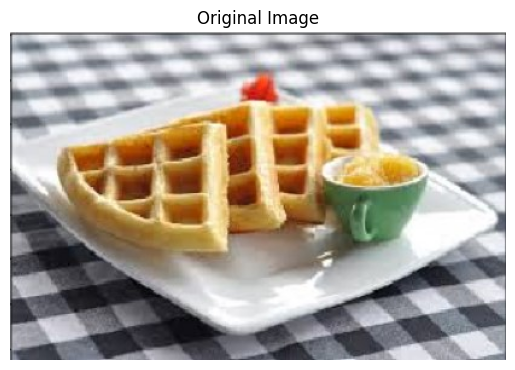

In [12]:
# Load the original image
image = cv2.imread('harris_corner_detection_image.jpg')

# Convert BGR to RGB for correct color display
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Display the image
plt.imshow(image_rgb)
plt.title("Original Image")
plt.axis("off")
plt.savefig("Original_Image.png")
plt.show()

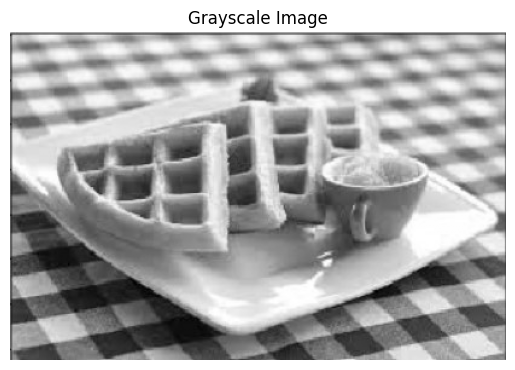

In [13]:
# Convert the original image to grayscale
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# Display the grayscale image
plt.imshow(gray, cmap='gray')
plt.title("Grayscale Image")
plt.axis("off")
plt.show()

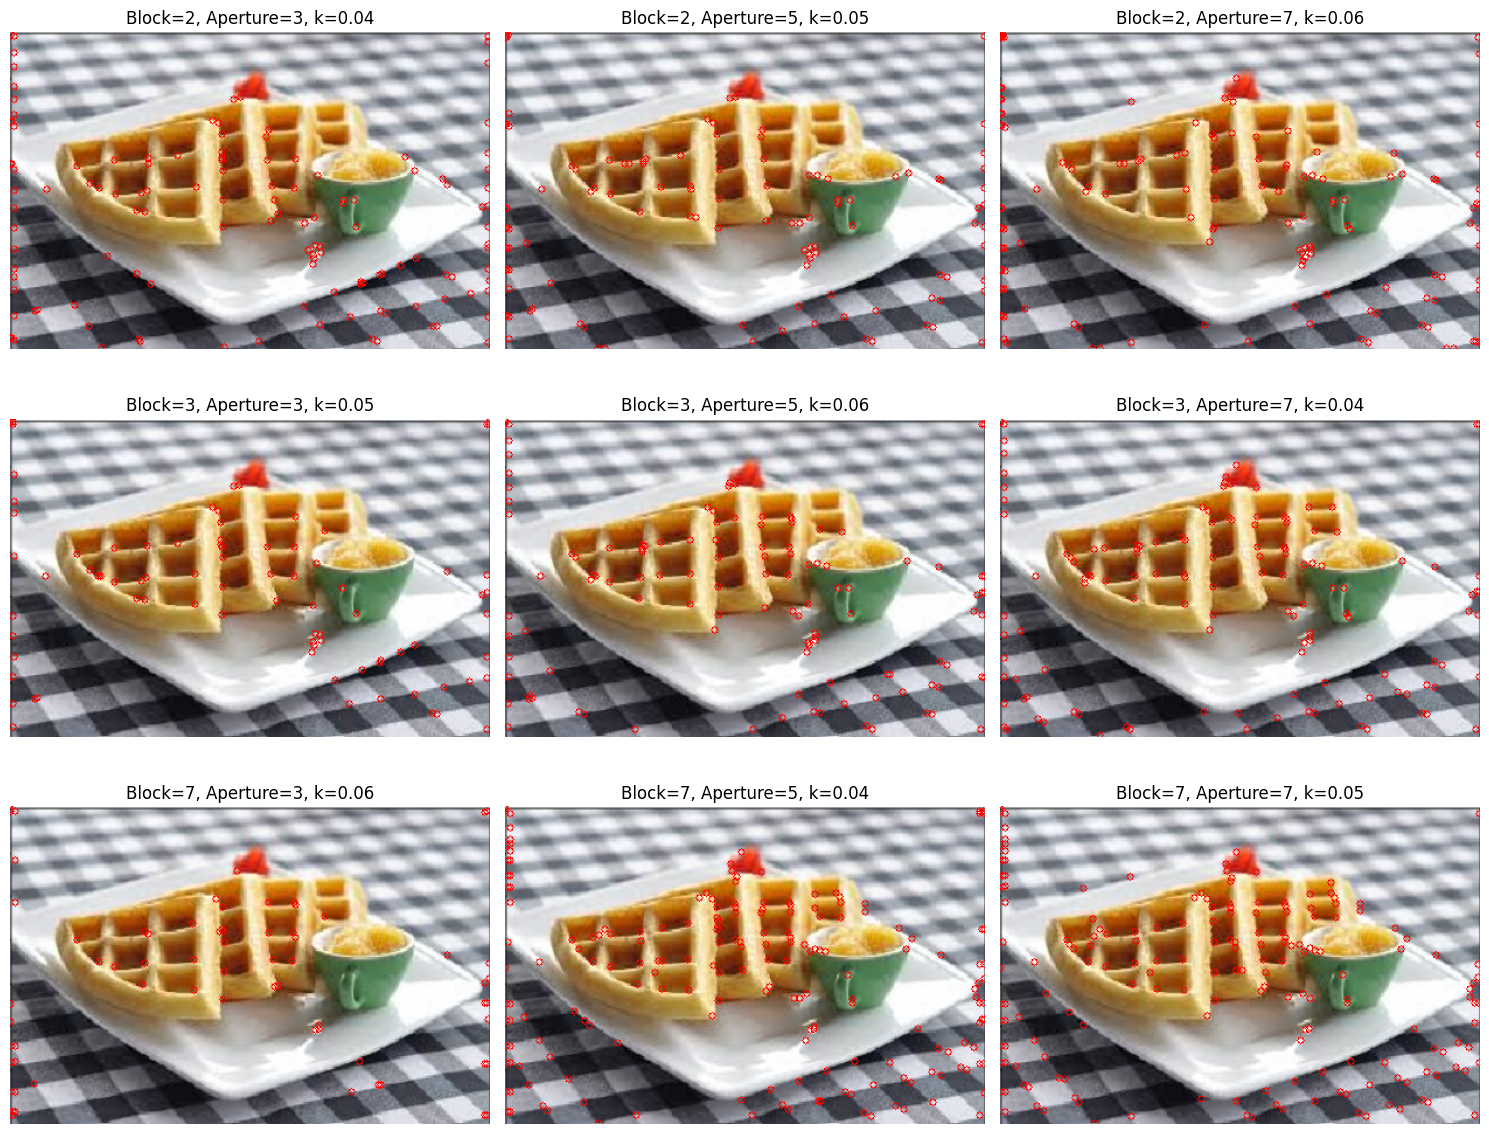

In [14]:
# Parameters to test
parameters = [
    (2, 3, 0.04),
    (2, 5, 0.05),
    (2, 7, 0.06),
    (3, 3, 0.05),
    (3, 5, 0.06),
    (3, 7, 0.04),
    (7, 3, 0.06),
    (7, 5, 0.04),
    (7, 7, 0.05)
]

threshold = 0.05

plt.figure(figsize=(15, 12))

for i, (block, aperture, k) in enumerate(parameters):

    # Harris Corner Detection
    corners = cv2.cornerHarris(gray, block, aperture, k)

    # Non-Maximum Suppression
    local_max = cv2.dilate(corners, None)

    # Threshold and NMS
    mask = (corners > threshold * corners.max()) & (corners == local_max)

    # Draw circles
    result = image.copy()
    y, x = np.where(mask)

    for a, b in zip(x, y):
        cv2.circle(result, (a, b), 3, (0, 0, 255), 1)

    # Display result
    plt.subplot(3, 3, i + 1)
    plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
    plt.title(f"Block={block}, Aperture={aperture}, k={k}")
    plt.axis("off")

plt.tight_layout()
plt.savefig("Harris_9_Results.png", dpi=200)
plt.show()